# Punjab Stubble Burning Fire Prediction

**Course:** INT234 Predictive Analytics

**Project goal:** Use past satellite fire detections to predict whether a grid cell in Punjab may have a fire detection on the next day.

This notebook follows a simple workflow: load data, clean it, explore patterns, create features, train machine learning models, compare results and test the selected model on 2025 data.

**Note:** Satellite fire detections are not confirmed cases of stubble burning.

### How to run this notebook

1. Keep the CSV file in `data/raw/` or in the same folder as this notebook. Its name should contain `Punjab_Fire`.
2. Run the cells from top to bottom.
3. The notebook creates the processed data, tables, graphs and saved model inside the project folders.
4. The project uses fire history, nearby grid cells and date information. It does not need an external weather API.


## 1. Imports, settings, helper functions and model list

In [1]:
# Import the libraries used in this project
import json
import joblib
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score,
    roc_auc_score, log_loss, accuracy_score, precision_recall_curve,
    confusion_matrix, mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)
from sklearn.model_selection import ParameterGrid
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

### Settings\nThis cell stores the main project settings, such as folders, years, grid size and graph colours. Usually, you do not need to change anything here.

In [2]:
# settings.py
# All the settings of the project are kept here.
# If you want to change something (years, grid size, colours), change it here only.


# ---------- folders ----------
BASE_DIR = Path.cwd()      # the folder where this notebook is
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
FIG_DIR = BASE_DIR / "outputs" / "figures"
TABLE_DIR = BASE_DIR / "outputs" / "tables"
MODEL_DIR = BASE_DIR / "outputs" / "models"

for folder in [RAW_DIR, PROCESSED_DIR, FIG_DIR, TABLE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


# ---------- fire data cleaning ----------
KEEP_TYPES = [0]                 # type 0 = vegetation fire. Other types are other land sources
KEEP_CONFIDENCE = ["n", "h"]     # n = nominal, h = high. We drop l = low
LAT_MIN, LAT_MAX = 29.5, 32.6    # Punjab box (the data already lies inside this)
LON_MIN, LON_MAX = 73.8, 77.0

# ---------- grid ----------
GRID_SIZE = 0.25                 # one grid cell is about 27 km

# ---------- calendar ----------
CALENDAR_START = "08-01"         # we build the table from 1 Aug ...
CALENDAR_END = "12-31"           # ... to 31 Dec of every year
SEASON_MONTHS = [10, 11]         # we predict only for October and November

# ---------- time based split (no random split!) ----------
TRAIN_YEARS = [2020, 2021, 2022, 2023]
VALID_YEARS = [2024]
TEST_YEARS = [2025]              # touched only once, in script 10

RANDOM_SEED = 42
SHOW_PLOTS = True                # set False if you only want the png files

# ---------- colours (fire theme) ----------
DEEP_RED = "#6A040F"
RED = "#C1121F"
ORANGE = "#F77F00"
AMBER = "#FCBF49"
TEAL = "#2A9D8F"                 # used for "no fire" / baselines so they look different
NAVY = "#264653"
GREY = "#8D99AE"

FIRE_COLOURS = [DEEP_RED, RED, ORANGE, AMBER]

### Helper functions\nThese are small reusable functions for loading data, cleaning it, making graphs and preparing model inputs. Other cells use these functions.

In [3]:
# helpers.py
# Simple helper functions used in the fire prediction project.
# The main notebook must define the imports and settings before using this file.

# -------------------- Plot settings --------------------

def set_plot_style():
    """Set a clean style for all graphs."""
    sns.set_theme(style="whitegrid")
    plt.rcParams["figure.figsize"] = (10, 5.5)
    plt.rcParams["axes.titlesize"] = 14
    plt.rcParams["axes.labelsize"] = 11
    plt.rcParams["axes.spines.top"] = False
    plt.rcParams["axes.spines.right"] = False


def save_figure(name):
    """Save a graph and show it if SHOW_PLOTS is True."""
    plt.tight_layout()
    file_path = FIG_DIR / (name + ".png")
    plt.savefig(file_path, dpi=150, bbox_inches="tight")
    print("Saved graph:", file_path.name)

    if SHOW_PLOTS:
        plt.show()

    plt.close()


# -------------------- Read and clean the data --------------------

def find_fire_file():
    """Find the fire CSV file in the raw folder or notebook folder."""
    files = list(RAW_DIR.glob("*Punjab_Fire*.csv"))

    if len(files) == 0:
        files = list(BASE_DIR.glob("*Punjab_Fire*.csv"))

    if len(files) == 0:
        raise FileNotFoundError(
            "CSV file not found. Put the Punjab_Fire CSV in data/raw "
            "or in the same folder as this notebook."
        )

    return files[0]


def load_fire_data():
    """Read the CSV file and convert its date column."""
    df = pd.read_csv(find_fire_file())
    df["date"] = pd.to_datetime(df["acq_date"])
    return df


def clean_fire_data(df):
    """Remove duplicate, unwanted and out-of-region fire records."""
    report = []
    report.append(("Original rows", len(df)))

    df = df.drop_duplicates()
    report.append(("After removing duplicates", len(df)))

    df = df[df["type"].isin(KEEP_TYPES)].copy()
    report.append(("After keeping vegetation fires", len(df)))

    df = df[df["confidence"].isin(KEEP_CONFIDENCE)].copy()
    report.append(("After removing low-confidence records", len(df)))

    inside_punjab = (
        df["latitude"].between(LAT_MIN, LAT_MAX)
        & df["longitude"].between(LON_MIN, LON_MAX)
    )
    df = df[inside_punjab].copy()
    report.append(("After keeping the Punjab region", len(df)))

    # Give every fire point a grid-cell number.
    df["year"] = df["date"].dt.year
    df["cell_row"] = np.floor(df["latitude"] / GRID_SIZE).astype(int)
    df["cell_col"] = np.floor(df["longitude"] / GRID_SIZE).astype(int)
    df["cell_id"] = (
        df["cell_row"].astype(str) + "_" + df["cell_col"].astype(str)
    )

    report = pd.DataFrame(report, columns=["Step", "Rows"])
    return df, report


# -------------------- Make one row for each cell and day --------------------

def make_cell_day_table(fires):
    """Add zero-fire days for each grid cell."""
    # Use training years to decide which cells are included.
    training_fires = fires[fires["year"].isin(TRAIN_YEARS)]
    cells = training_fires[
        ["cell_id", "cell_row", "cell_col"]
    ].drop_duplicates()

    # Count detections in each cell on each date.
    daily = fires.groupby(["cell_id", "date"]).agg(
        fire_count=("frp", "size"),
        frp_sum=("frp", "sum"),
        frp_max=("frp", "max")
    ).reset_index()

    # Create the dates from August to December for every year.
    all_days = []
    for year in sorted(fires["year"].unique()):
        start_date = str(year) + "-" + CALENDAR_START
        end_date = str(year) + "-" + CALENDAR_END
        year_days = pd.date_range(start_date, end_date)
        all_days.extend(year_days)

    days_table = pd.DataFrame({"date": all_days})

    # Combine every cell with every date.
    table = cells.merge(days_table, how="cross")
    table = table.merge(daily, on=["cell_id", "date"], how="left")

    # If no fire was detected, set the count and FRP values to zero.
    for column in ["fire_count", "frp_sum", "frp_max"]:
        table[column] = table[column].fillna(0)

    table["year"] = table["date"].dt.year
    table["cell_lat"] = (table["cell_row"] + 0.5) * GRID_SIZE
    table["cell_lon"] = (table["cell_col"] + 0.5) * GRID_SIZE

    return table.sort_values(
        ["cell_id", "date"]
    ).reset_index(drop=True)


# -------------------- Feature names --------------------

CALENDAR = ["day_of_year"]
LOCATION = ["cell_lat", "cell_lon"]

HISTORY = [
    "fire_today", "fire_lag1", "fire_lag2",
    "fire_roll3", "fire_roll7", "days_since_fire", "frp_roll3"
]

NEIGHBOUR = ["neighbour_today", "neighbour_roll3"]


def days_since_event(values):
    """Count days since the last event. The maximum value is 30."""
    result = np.full(len(values), 30.0)
    last_event = None

    for i in range(len(values)):
        if values[i] > 0:
            last_event = i

        if last_event is not None:
            result[i] = min(i - last_event, 30)

    return result


# -------------------- Add information from nearby cells --------------------

def add_neighbour_features(table):
    """Count fires in the eight surrounding grid cells."""
    wide = table.pivot(
        index="date",
        columns="cell_id",
        values="fire_count"
    )

    positions = table.drop_duplicates("cell_id").set_index("cell_id")
    positions = positions[["cell_row", "cell_col"]]

    # Match each grid position with its cell ID.
    position_to_cell = {}
    for cell_id in positions.index:
        row = positions.loc[cell_id, "cell_row"]
        col = positions.loc[cell_id, "cell_col"]
        position_to_cell[(row, col)] = cell_id

    neighbour_counts = pd.DataFrame(
        0.0, index=wide.index, columns=wide.columns
    )

    for cell_id in wide.columns:
        row = positions.loc[cell_id, "cell_row"]
        col = positions.loc[cell_id, "cell_col"]
        nearby_cells = []

        # Check the eight cells around the current cell.
        for row_change in [-1, 0, 1]:
            for col_change in [-1, 0, 1]:
                if row_change == 0 and col_change == 0:
                    continue

                nearby_id = position_to_cell.get(
                    (row + row_change, col + col_change)
                )

                if nearby_id is not None:
                    nearby_cells.append(nearby_id)

        if nearby_cells:
            neighbour_counts[cell_id] = wide[nearby_cells].sum(axis=1)

    # Calculate the nearby fire count over the last three days.
    # Reset the rolling calculation at the start of each year.
    years = pd.Series(wide.index.year, index=wide.index)
    neighbour_roll3 = neighbour_counts.groupby(years).rolling(
        3, min_periods=1
    ).sum()
    neighbour_roll3.index = neighbour_roll3.index.droplevel(0)

    today = (
        neighbour_counts.stack()
        .rename("neighbour_today")
        .reset_index()
    )
    recent = (
        neighbour_roll3.stack()
        .rename("neighbour_roll3")
        .reset_index()
    )

    neighbour_data = today.merge(
        recent, on=["date", "cell_id"]
    )

    return table.merge(
        neighbour_data,
        on=["date", "cell_id"],
        how="left"
    )


# -------------------- Create model features and target --------------------

def build_features(table):
    """Create past-information features and the next-day prediction target."""
    result = table.sort_values(
        ["cell_id", "date"]
    ).reset_index(drop=True).copy()

    group = result.groupby(["cell_id", "year"])

    # Fire information from today and previous days.
    result["fire_today"] = result["fire_count"]
    result["fire_lag1"] = group["fire_count"].shift(1).fillna(0)
    result["fire_lag2"] = group["fire_count"].shift(2).fillna(0)

    result["fire_roll3"] = group["fire_count"].transform(
        lambda values: values.rolling(3, min_periods=1).sum()
    )
    result["fire_roll7"] = group["fire_count"].transform(
        lambda values: values.rolling(7, min_periods=1).sum()
    )
    result["frp_roll3"] = group["frp_sum"].transform(
        lambda values: values.rolling(3, min_periods=1).sum()
    )
    result["days_since_fire"] = group["fire_count"].transform(
        lambda values: days_since_event(values.values)
    )

    # Add information from nearby cells.
    result = add_neighbour_features(result)

    # Add date information.
    result["day_of_year"] = result["date"].dt.dayofyear
    result["week"] = result["day_of_year"] // 7

    # The target is whether a fire is detected on the next day.
    group = result.groupby(["cell_id", "year"])
    next_day_count = group["fire_count"].shift(-1)

    result["count_next_day"] = next_day_count
    result["fire_next_day"] = np.where(
        next_day_count.isna(),
        np.nan,
        (next_day_count > 0).astype(float)
    )

    return result


# -------------------- Split the data by year --------------------

def add_split_column(table):
    """Label each row as training, validation or testing data."""
    result = table.copy()
    result["split"] = "none"

    result.loc[result["year"].isin(TRAIN_YEARS), "split"] = "train"
    result.loc[result["year"].isin(VALID_YEARS), "split"] = "valid"
    result.loc[result["year"].isin(TEST_YEARS), "split"] = "test"

    return result


def keep_season_rows(table):
    """Keep October and November rows with a known next-day result."""
    result = table[table["date"].dt.month.isin(SEASON_MONTHS)]
    result = result[result["fire_next_day"].notna()]
    return result.reset_index(drop=True)


# -------------------- Choose feature columns --------------------

def get_feature_sets(columns):
    """Return the feature groups used by the project."""
    feature_sets = {
        "1 Calendar + location": CALENDAR + LOCATION,
        "2 + Fire history": CALENDAR + LOCATION + HISTORY,
        "3 + Neighbour fires": (
            CALENDAR + LOCATION + HISTORY + NEIGHBOUR
        )
    }

    return feature_sets


def all_feature_columns(columns):
    """Return all available feature columns."""
    feature_sets = get_feature_sets(columns)
    last_group = list(feature_sets.keys())[-1]
    return feature_sets[last_group]


# -------------------- Evaluate model predictions --------------------

def get_scores(y_true, y_score, threshold=0.5, is_probability=True):
    """Calculate common classification scores."""
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    y_pred = (y_score >= threshold).astype(int)

    scores = {
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "pr_auc": average_precision_score(y_true, y_score),
        "accuracy": accuracy_score(y_true, y_pred)
    }

    # ROC-AUC needs both classes to be present.
    if len(np.unique(y_true)) == 2:
        scores["roc_auc"] = roc_auc_score(y_true, y_score)
    else:
        scores["roc_auc"] = np.nan

    if is_probability and len(np.unique(y_true)) == 2:
        scores["log_loss"] = log_loss(
            y_true, np.clip(y_score, 1e-4, 1 - 1e-4)
        )
    else:
        scores["log_loss"] = np.nan

    return scores


def best_threshold(y_true, y_score):
    """Find the threshold that gives the highest F1 score."""
    precision, recall, thresholds = precision_recall_curve(
        y_true, y_score
    )

    if len(thresholds) == 0:
        return 0.5

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    return float(thresholds[int(np.argmax(f1_values))])


# -------------------- Compare with simple baselines --------------------

def baseline_scores(train, other):
    """Make simple predictions to compare with the ML models."""
    results = {}

    # Baseline 1: predict that there will be no fire.
    results["Baseline: always no fire"] = (
        np.zeros(len(other)), False
    )

    # Baseline 2: predict fire if there is fire today.
    results["Baseline: fire today"] = (
        (other["fire_today"] > 0).astype(float).values, False
    )

    # Baseline 3: predict fire if there was fire in the last three days.
    results["Baseline: fire in last 3 days"] = (
        (other["fire_roll3"] > 0).astype(float).values, False
    )

    # Baseline 4: use the average fire rate for the same cell and week.
    cell_week_rate = (
        train.groupby(["cell_id", "week"])["fire_next_day"]
        .mean()
        .rename("rate")
        .reset_index()
    )

    week_rate = (
        train.groupby("week")["fire_next_day"]
        .mean()
        .rename("week_rate")
        .reset_index()
    )

    temp = other[["cell_id", "week"]].merge(
        cell_week_rate, on=["cell_id", "week"], how="left"
    )
    temp = temp.merge(week_rate, on="week", how="left")

    average_rate = (
        temp["rate"]
        .fillna(temp["week_rate"])
        .fillna(train["fire_next_day"].mean())
    )

    results["Baseline: seasonal average"] = (
        average_rate.values, True
    )

    return results

### Machine learning models\nWe compare 7 classification models. The notebook checks model settings using earlier years, then compares the models on 2024 data.

In [4]:
# model_recipes.py
# The list of classifiers we try (all are from the INT234 syllabus) and a small
# tuning function that respects time order.



# newer scikit-learn versions print a warning about SVC(probability=True). We hide it.
warnings.filterwarnings("ignore", category=FutureWarning)


def make_pipe(model, scale):
    # scaling is only needed for models that compare distances or use weights
    if scale:
        return Pipeline([("scale", StandardScaler()), ("model", model)])
    return Pipeline([("model", model)])


def get_recipes():
    seed = RANDOM_SEED
    return {
        "Logistic Regression": {
            "pipe": make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced"), True),
            "grid": {"model__C": [0.1, 1, 10]},
            "max_rows": None},
        "KNN": {
            "pipe": make_pipe(KNeighborsClassifier(), True),
            "grid": {"model__n_neighbors": [5, 15, 31]},
            "max_rows": None},
        "Naive Bayes": {
            "pipe": make_pipe(GaussianNB(), False),
            "grid": {"model__var_smoothing": [1e-9, 1e-7, 1e-5]},
            "max_rows": None},
        "Decision Tree": {
            "pipe": make_pipe(DecisionTreeClassifier(class_weight="balanced", random_state=seed), False),
            "grid": {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [10, 50]},
            "max_rows": None},
        "Random Forest": {
            "pipe": make_pipe(RandomForestClassifier(class_weight="balanced", random_state=seed, n_jobs=-1), False),
            "grid": {"model__n_estimators": [100, 200], "model__max_depth": [6, 10],
                     "model__min_samples_leaf": [5, 20]},
            "max_rows": None},
        # SVM is slow on big data, so we use a random sample of 6000 rows
        "SVM": {
            "pipe": make_pipe(SVC(probability=True, class_weight="balanced", random_state=seed), True),
            "grid": {"model__C": [0.5, 2]},
            "max_rows": 6000},
        "MLP (neural network)": {
            "pipe": make_pipe(MLPClassifier(max_iter=300, early_stopping=True, random_state=seed), True),
            "grid": {"model__hidden_layer_sizes": [(16,), (32, 16)], "model__alpha": [0.0001, 0.01]},
            "max_rows": None},
    }


def shrink(data, max_rows):
    if max_rows is not None and len(data) > max_rows:
        return data.sample(max_rows, random_state=RANDOM_SEED)
    return data


def tune(pipe, grid, train, feature_cols, max_rows=None):
    """
    Choose model settings using 2020-2022 for training
    and 2023 for checking. 2024 stays separate for model comparison.
    """
    years = sorted(train["year"].unique())
    fit_part = train[train["year"].isin(years[:-1])]
    check_part = train[train["year"] == years[-1]]
    fit_part = shrink(fit_part, max_rows)

    all_params = []
    all_scores = []

    for params in ParameterGrid(grid):
        model = clone(pipe).set_params(**params)
        model.fit(fit_part[feature_cols], fit_part["fire_next_day"])
        probabilities = model.predict_proba(check_part[feature_cols])[:, 1]
        score = average_precision_score(check_part["fire_next_day"], probabilities)
        all_params.append(params)
        all_scores.append(score)

    best_index = int(np.argmax(all_scores))
    tuning_table = pd.DataFrame({
        "settings": [str(p) for p in all_params],
        "PR-AUC on 2023": all_scores
    })
    tuning_table = tuning_table.sort_values(
        "PR-AUC on 2023", ascending=False
    ).reset_index(drop=True)

    return all_params[best_index], all_scores[best_index], tuning_table

## 2. Phase 1: Explore the raw data (INT234 Practical 1)

Phase 1 / Practical 1: look at the raw fire data before doing anything with it.

In [5]:
# imports
set_plot_style()

In [6]:
# load the data
fires = load_fire_data()
print("File used:", find_fire_file().name)
print("Rows and columns:", fires.shape)
print()
print(fires.head())

File used: Punjab_Fire_Data_Combined_2020_2025.csv
Rows and columns: (295685, 17)

   latitude  longitude  brightness  scan  track    acq_date  acq_time  \
0  30.61414   73.89183      334.98  0.38   0.36  2020-08-03       808   
1  30.76861   74.19826      336.06  0.38   0.36  2020-08-03       808   
2  31.25200   76.92764      305.41  0.40   0.37  2020-08-03      2032   
3  31.25934   76.92464      302.31  0.40   0.37  2020-08-03      2032   
4  32.48193   74.31785      314.75  0.50   0.41  2020-08-03      2031   

  satellite instrument confidence  version  bright_t31   frp daynight  type  \
0      SNPP       SNPP          n        2      301.69  2.76        D     0   
1      SNPP       SNPP          n        2      302.92  2.81        D     0   
2      SNPP       SNPP          n        2      289.11  0.48        N     0   
3      SNPP       SNPP          n        2      289.26  0.55        N     2   
4      SNPP       SNPP          n        2      288.02  1.59        N     0   

   

In [7]:
# column types and missing values
print(fires.dtypes)
print()
print("Missing values in each column:")
print(fires.isna().sum())

latitude              float64
longitude             float64
brightness            float64
scan                  float64
track                 float64
acq_date                  str
acq_time                int64
satellite                 str
instrument                str
confidence                str
version                 int64
bright_t31            float64
frp                   float64
daynight                  str
type                    int64
source_file               str
date           datetime64[us]
dtype: object

Missing values in each column:
latitude       0
longitude      0
brightness     0
scan           0
track          0
acq_date       0
acq_time       0
satellite      0
instrument     0
confidence     0
version        0
bright_t31     0
frp            0
daynight       0
type           0
source_file    0
date           0
dtype: int64


In [8]:
# basic numbers
print(fires[["latitude", "longitude", "brightness", "frp"]].describe().round(2))
print()
print("First date:", fires["date"].min().date())
print("Last date :", fires["date"].max().date())
print()
for col in ["satellite", "confidence", "type", "daynight"]:
    print(fires[col].value_counts())
    print()

        latitude  longitude  brightness        frp
count  295685.00  295685.00   295685.00  295685.00
mean       30.64      75.23      338.87       6.84
std         0.63       0.69        9.39       6.82
min        29.50      73.85      208.00       0.14
25%        30.19      74.70      333.26       3.14
50%        30.53      75.21      337.05       4.83
75%        30.99      75.73      342.68       7.97
max        32.55      76.95      367.00     296.83

First date: 2020-08-03
Last date : 2025-12-30

satellite
SNPP    295685
Name: count, dtype: int64

confidence
n    268590
l     14965
h     12130
Name: count, dtype: int64

type
0    293839
2      1844
3         2
Name: count, dtype: int64

daynight
D    291362
N      4323
Name: count, dtype: int64



Saved graph: 01_fires_per_year.png


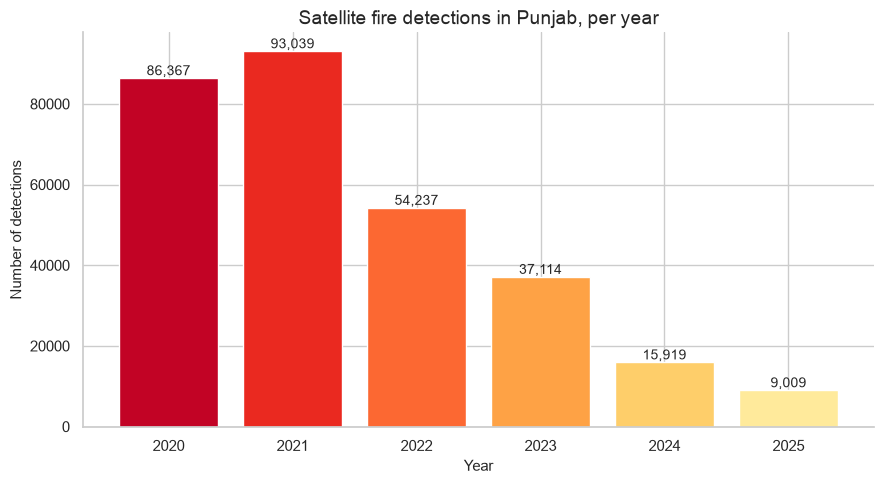

In [10]:
# graph 1: fires per year
per_year = fires.groupby(fires["date"].dt.year).size()

plt.figure(figsize=(9, 5))
bars = plt.bar(per_year.index.astype(str), per_year.values,
               color=sns.color_palette("YlOrRd_r", len(per_year)))
for bar, value in zip(bars, per_year.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}",
             ha="center", va="bottom", fontsize=10)
plt.title("Satellite fire detections in Punjab, per year")
plt.xlabel("Year")
plt.ylabel("Number of detections")
save_figure("01_fires_per_year")

In [11]:
# what did we learn
print("Things to remember:")
print("1. The file has only fire points. Days with no fire are not in the file.")
print("2. Days without a detection are added later as zero-fire days.")
print("3. The satellite passes at fixed times, so the counts are not complete.")

Things to remember:
1. The file has only fire points. Days with no fire are not in the file.
2. Days without a detection are added later as zero-fire days.
3. The satellite passes at fixed times, so the counts are not complete.


## 3. Phase 2: Clean the data and make the cell-day table (INT234 Practical 2)

Phase 2 / Practical 2: clean the fire data and make the cell-day table.
One row of the new table = one grid cell on one day.

In [12]:
# step 1: load and clean
fires = load_fire_data()
clean, report = clean_fire_data(fires)

print("Cleaning report:")
print(report.to_string(index=False))
report.to_csv(TABLE_DIR / "02_cleaning_report.csv", index=False)

Cleaning report:
                                 Step   Rows
                        Original rows 295685
            After removing duplicates 295685
       After keeping vegetation fires 293839
After removing low-confidence records 278879
      After keeping the Punjab region 278879


In [13]:
# step 2: how many cells do we have?
cells = clean[clean["year"].isin(TRAIN_YEARS)]["cell_id"].nunique()
print()
print("Grid size:", GRID_SIZE, "degree")
print("Cells with at least one fire in the training years:", cells)


Grid size: 0.25 degree
Cells with at least one fire in the training years: 166


In [14]:
# step 3: make the cell-day table
table = make_cell_day_table(clean)
print()
print("Cell-day table shape:", table.shape)
print(table.head())

# check: rows should be cells x days
days_per_year = table.groupby("year")["date"].nunique()
print()
print("Days per year in the table:")
print(days_per_year)
print("Cells x days =", table["cell_id"].nunique() * table["date"].nunique(),
      "| rows in table =", len(table))


Cell-day table shape: (152388, 10)
   cell_id  cell_row  cell_col       date  fire_count  frp_sum  frp_max  year  \
0  118_296       118       296 2020-08-01         0.0      0.0      0.0  2020   
1  118_296       118       296 2020-08-02         0.0      0.0      0.0  2020   
2  118_296       118       296 2020-08-03         0.0      0.0      0.0  2020   
3  118_296       118       296 2020-08-04         0.0      0.0      0.0  2020   
4  118_296       118       296 2020-08-05         0.0      0.0      0.0  2020   

   cell_lat  cell_lon  
0    29.625    74.125  
1    29.625    74.125  
2    29.625    74.125  
3    29.625    74.125  
4    29.625    74.125  

Days per year in the table:
year
2020    153
2021    153
2022    153
2023    153
2024    153
2025    153
Name: date, dtype: int64
Cells x days = 152388 | rows in table = 152388


In [15]:
# step 4: simple quality checks
print()
print("Missing values in table:", int(table.isna().sum().sum()))
print("Negative fire counts   :", int((table["fire_count"] < 0).sum()))
print("Days with a fire (share of all cell-days):",
      round((table["fire_count"] > 0).mean(), 3))

# fires that were thrown away because their cell is not in the list
kept = table["fire_count"].sum()
lost = len(clean) - kept
print("Clean fire points:", len(clean), "| inside table:", int(kept), "| outside the cells:", int(lost))


Missing values in table: 0
Negative fire counts   : 0
Days with a fire (share of all cell-days): 0.174
Clean fire points: 278879 | inside table: 278872 | outside the cells: 7


In [16]:
# step 5: save
table.to_csv(PROCESSED_DIR / "cell_day.csv", index=False)
print()
print("Saved: data/processed/cell_day.csv")


Saved: data/processed/cell_day.csv


## 4. Feature creation and time split

Create information from past fire activity and use the next day as the prediction target.

The idea: standing on day d, we can only use what we know till day d.
The target is "will the cell have a fire on day d+1?".

In [17]:
# Load the cell-day table
table = pd.read_csv(PROCESSED_DIR / "cell_day.csv", parse_dates=["date"])
print("Cell-day data loaded.")
print("Rows and columns:", table.shape)

Cell-day data loaded.
Rows and columns: (152388, 10)


In [18]:
# build features and target
features = build_features(table)
features = add_split_column(features)

In [19]:
# Check that future fire data does not change past features
def check_no_future_leak(table, feature_cols):
    cut_date = pd.Timestamp("2023-11-10")
    changed = table.copy()

    future_rows = changed["date"] > cut_date
    for column in ["fire_count", "frp_sum", "frp_max"]:
        changed.loc[future_rows, column] = 0

    original_features = build_features(table)
    changed_features = build_features(changed)

    original_past = original_features[
        original_features["date"] <= cut_date
    ][feature_cols].fillna(-1).values

    changed_past = changed_features[
        changed_features["date"] <= cut_date
    ][feature_cols].fillna(-1).values

    return np.allclose(original_past, changed_past)


feature_cols = all_feature_columns(features.columns)
passed = check_no_future_leak(table, feature_cols)
print("Leakage check:", "PASSED" if passed else "FAILED")

if not passed:
    raise ValueError("The leakage check failed. Review the feature code.")

Leakage check: PASSED


In [20]:
# Keep October and November rows with a known next-day target
model_data = keep_season_rows(features)

In [21]:
# check the result
print()
print("Final table shape:", model_data.shape)
print()
balance = model_data.groupby(["split", "year"]).agg(
    rows=("fire_next_day", "size"),
    fire_share=("fire_next_day", "mean")).round(3)
print("Share of cell-days that had a fire the next day:")
print(balance)
balance.to_csv(TABLE_DIR / "04_class_balance.csv")

print()
print("Missing values in the features:", int(model_data[feature_cols].isna().sum().sum()))
print("Features used:", len(feature_cols))
print(feature_cols)


Final table shape: (60756, 24)

Share of cell-days that had a fire the next day:
             rows  fire_share
split year                   
test  2025  10126       0.250
train 2020  10126       0.474
      2021  10126       0.463
      2022  10126       0.393
      2023  10126       0.363
valid 2024  10126       0.314

Missing values in the features: 0
Features used: 12
['day_of_year', 'cell_lat', 'cell_lon', 'fire_today', 'fire_lag1', 'fire_lag2', 'fire_roll3', 'fire_roll7', 'days_since_fire', 'frp_roll3', 'neighbour_today', 'neighbour_roll3']


In [22]:
# save
keep = (["cell_id", "date", "year", "split", "week", "fire_next_day", "count_next_day"]
        + feature_cols + ["fire_count", "frp_sum"])
keep = list(dict.fromkeys(keep))            # remove repeated names, keep order
model_data[keep].to_csv(PROCESSED_DIR / "features.csv", index=False)
print()
print("Saved: data/processed/features.csv")


Saved: data/processed/features.csv


## 5. Exploratory Data Analysis

Phase 3: Exploratory Data Analysis (EDA) with Matplotlib and Seaborn.

In [23]:
# load data
fires, _ = clean_fire_data(load_fire_data())
data = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"])
train = data[data["split"] == "train"]

print("Clean fire points:", len(fires), "| model rows:", len(data))

Clean fire points: 278879 | model rows: 60756


Saved graph: 05_fire_density_map.png


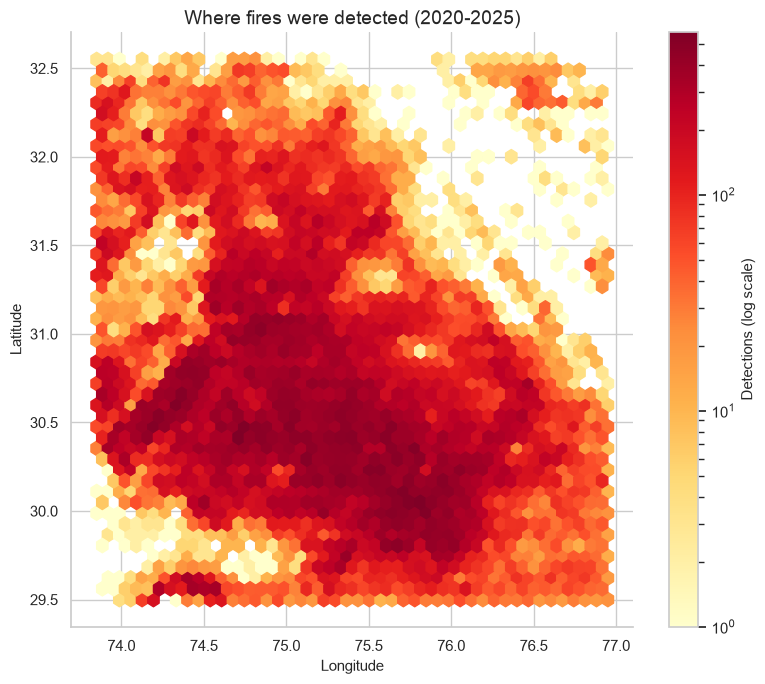

In [24]:
# graph 2: where are the fires? (all clean detections)
plt.figure(figsize=(8, 7))
hb = plt.hexbin(fires["longitude"], fires["latitude"], gridsize=45, cmap="YlOrRd",
                bins="log", mincnt=1)
plt.colorbar(hb, label="Detections (log scale)")
plt.title("Where fires were detected (2020-2025)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
save_figure("05_fire_density_map")

Saved graph: 05_class_balance_by_year.png


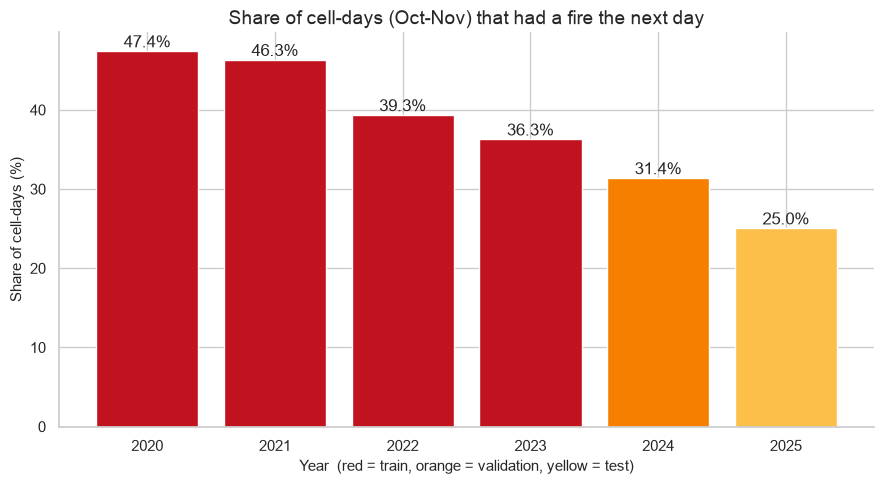

The share goes down every year, so the test year (2025) is different from the training years.


In [25]:
# graph 3: how many fire days do we have each year? (class balance)
balance = data.groupby("year")["fire_next_day"].mean().reset_index()

plt.figure(figsize=(9, 5))
bars = plt.bar(balance["year"].astype(str), balance["fire_next_day"] * 100,
               color=[RED if y in TRAIN_YEARS else (ORANGE if y in VALID_YEARS else AMBER)
                      for y in balance["year"]])
for bar, value in zip(bars, balance["fire_next_day"] * 100):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.5, f"{value:.1f}%", ha="center")
plt.title("Share of cell-days (Oct-Nov) that had a fire the next day")
plt.xlabel("Year  (red = train, orange = validation, yellow = test)")
plt.ylabel("Share of cell-days (%)")
save_figure("05_class_balance_by_year")
print("The share goes down every year, so the test year (2025) is different from the training years.")

Saved graph: 05_correlation_heatmap.png


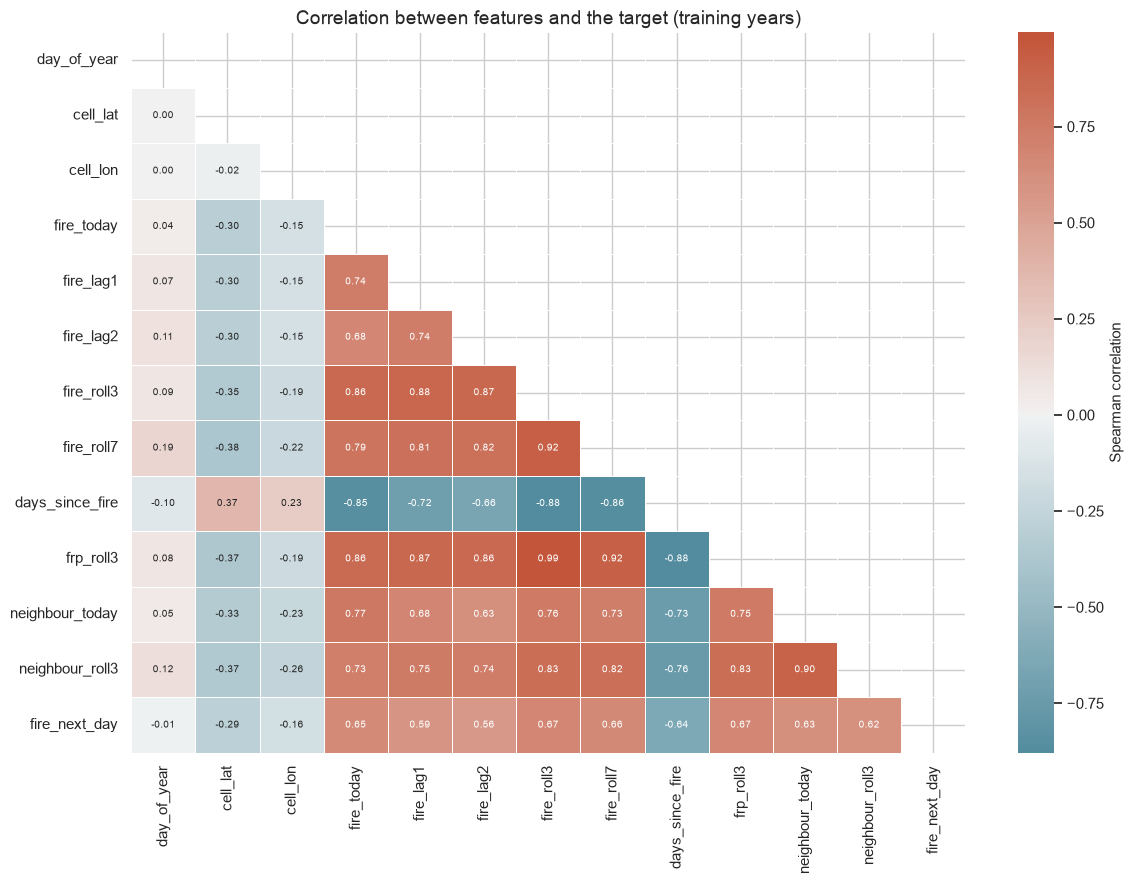

In [26]:
# graph 6: correlation heatmap (training years only)
feature_cols = all_feature_columns(data.columns)
corr = train[feature_cols + ["fire_next_day"]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(220, 20, as_cmap=True), center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5,
            cbar_kws={"label": "Spearman correlation"})
plt.title("Correlation between features and the target (training years)")
save_figure("05_correlation_heatmap")

## 6. Basic statistics\nThis section shows simple numerical summaries of the training data. The extra advanced statistical tests have been removed to keep the project easier to explain.

In [27]:
# Load training data for basic statistics
data = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"])
train = data[data["split"] == "train"].reset_index(drop=True)

test_cols = [
    "fire_roll7", "frp_roll3",
    "neighbour_roll3", "days_since_fire"
]

fire_yes = train[train["fire_next_day"] == 1]
fire_no = train[train["fire_next_day"] == 0]
print("Training rows:", len(train), "| fire next day:", len(fire_yes), "| no fire:", len(fire_no))

Training rows: 40504 | fire next day: 17144 | no fire: 23360


In [28]:
# 1. descriptive statistics
summary = train[test_cols].agg(["mean", "median", "std", "min", "max", "skew"]).T.round(2)
print()
print("DESCRIPTIVE STATISTICS (training years)")
print(summary)
summary.to_csv(TABLE_DIR / "06_descriptive_statistics.csv")


DESCRIPTIVE STATISTICS (training years)
                   mean  median     std  min      max  skew
fire_roll7        43.35     4.0  111.26  0.0  1251.00  4.70
frp_roll3        130.95     4.8  406.51  0.0  6165.79  5.66
neighbour_roll3  144.35    24.0  340.11  0.0  4115.00  4.61
days_since_fire    8.78     1.0   12.39  0.0    30.00  1.02


## 7. Classification models and comparison\nWe first compare simple baselines, then train 7 machine learning models. The models are compared using the 2024 validation data. The 2025 data is kept for the final test.

In [29]:
# load data
data = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"])
train = data[data["split"] == "train"].reset_index(drop=True)
valid = data[data["split"] == "valid"].reset_index(drop=True)

feature_cols = all_feature_columns(data.columns)
y_train = train["fire_next_day"]
y_valid = valid["fire_next_day"]

print("Train rows:", len(train), "| Valid rows:", len(valid))
print("Fire share in train:", round(y_train.mean(), 3), "| in valid:", round(y_valid.mean(), 3))
print("Features:", len(feature_cols), "->", feature_cols)

Train rows: 40504 | Valid rows: 10126
Fire share in train: 0.423 | in valid: 0.314
Features: 12 -> ['day_of_year', 'cell_lat', 'cell_lon', 'fire_today', 'fire_lag1', 'fire_lag2', 'fire_roll3', 'fire_roll7', 'days_since_fire', 'frp_roll3', 'neighbour_today', 'neighbour_roll3']


In [30]:
# step 1: baselines (no machine learning)
results = []
curves = {}                      # keep scores for the PR curve later

baselines = baseline_scores(train, valid)
for name, (score, is_prob) in baselines.items():
    if is_prob:
        threshold = best_threshold(y_valid, score)
    else:
        threshold = 0.5
    row = get_scores(y_valid, score, threshold, is_prob)
    row.update({"model": name, "type": "baseline", "threshold": threshold})
    results.append(row)
    curves[name] = score

print()
print(pd.DataFrame(results)[["model", "precision", "recall", "f1", "pr_auc"]].round(3).to_string(index=False))


                        model  precision  recall    f1  pr_auc
     Baseline: always no fire      0.000   0.000 0.000   0.314
         Baseline: fire today      0.615   0.618 0.617   0.500
Baseline: fire in last 3 days      0.505   0.818 0.625   0.470
   Baseline: seasonal average      0.517   0.811 0.632   0.581


In [31]:
# step 2: train and tune every model
recipes = get_recipes()
best_params = {}
fitted_models = {}
train_pr_auc = {}

for name, recipe in recipes.items():
    print()
    print("Tuning", name, "...")
    params, cv_score, tuning_table = tune(recipe["pipe"], recipe["grid"], train,
                                             feature_cols, recipe["max_rows"])
    best_params[name] = params
    print("   best settings:", params, "| PR-AUC on 2023:", round(cv_score, 3))

    # fit on all training years with the best settings
    model = clone(recipe["pipe"]).set_params(**params)
    fit_data = shrink(train, recipe["max_rows"])
    model.fit(fit_data[feature_cols], fit_data["fire_next_day"])
    fitted_models[name] = model

    # score on the validation year
    valid_prob = model.predict_proba(valid[feature_cols])[:, 1]
    threshold = best_threshold(y_valid, valid_prob)
    row = get_scores(y_valid, valid_prob, threshold)
    row.update({"model": name, "type": "model", "threshold": threshold})
    results.append(row)
    curves[name] = valid_prob

    # also score on the training data to see overfitting
    train_prob = model.predict_proba(train[feature_cols])[:, 1]
    train_pr_auc[name] = get_scores(y_train, train_prob, threshold)["pr_auc"]


Tuning Logistic Regression ...
   best settings: {'model__C': 10} | PR-AUC on 2023: 0.78

Tuning KNN ...
   best settings: {'model__n_neighbors': 31} | PR-AUC on 2023: 0.772

Tuning Naive Bayes ...
   best settings: {'model__var_smoothing': 1e-05} | PR-AUC on 2023: 0.778

Tuning Decision Tree ...
   best settings: {'model__max_depth': 8, 'model__min_samples_leaf': 50} | PR-AUC on 2023: 0.771

Tuning Random Forest ...
   best settings: {'model__max_depth': 6, 'model__min_samples_leaf': 5, 'model__n_estimators': 200} | PR-AUC on 2023: 0.787

Tuning SVM ...
   best settings: {'model__C': 2} | PR-AUC on 2023: 0.778

Tuning MLP (neural network) ...
   best settings: {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (32, 16)} | PR-AUC on 2023: 0.804


In [32]:
# step 3: comparison table
results = pd.DataFrame(results)
results["train_pr_auc"] = results["model"].map(train_pr_auc)
results = results.sort_values("pr_auc", ascending=False).reset_index(drop=True)

show = ["model", "type", "threshold", "precision", "recall", "f1", "pr_auc", "roc_auc", "log_loss", "accuracy"]
print()
print("VALIDATION RESULTS (year 2024), sorted by PR-AUC")
print(results[show].round(3).to_string(index=False))
results.to_csv(TABLE_DIR / "07_validation_results.csv", index=False)

models_only = results[results["type"] == "model"]
best_name = models_only.iloc[0]["model"]
best_baseline = results[results["type"] == "baseline"].iloc[0]
print()
print("Best model on validation:", best_name)
print("Best baseline           :", best_baseline["model"],
      "(PR-AUC", round(best_baseline["pr_auc"], 3), ")")
if models_only.iloc[0]["pr_auc"] <= best_baseline["pr_auc"]:
    print("WARNING: the best model does NOT beat the best baseline. Say this clearly in the report.")


VALIDATION RESULTS (year 2024), sorted by PR-AUC
                        model     type  threshold  precision  recall    f1  pr_auc  roc_auc  log_loss  accuracy
         MLP (neural network)    model      0.375      0.594   0.750 0.663   0.695    0.837     0.458     0.761
                Random Forest    model      0.364      0.571   0.785 0.661   0.687    0.840     0.460     0.748
                Decision Tree    model      0.393      0.592   0.763 0.667   0.684    0.834     0.479     0.761
                          SVM    model      0.233      0.549   0.798 0.650   0.671    0.818     0.487     0.731
          Logistic Regression    model      0.428      0.551   0.791 0.649   0.668    0.825     0.480     0.732
                          KNN    model      0.355      0.559   0.772 0.648   0.643    0.821     0.496     0.737
                  Naive Bayes    model      0.000      0.541   0.803 0.646   0.637    0.818     2.612     0.724
   Baseline: seasonal average baseline      0.400     

Saved graph: 07_pr_auc_comparison.png


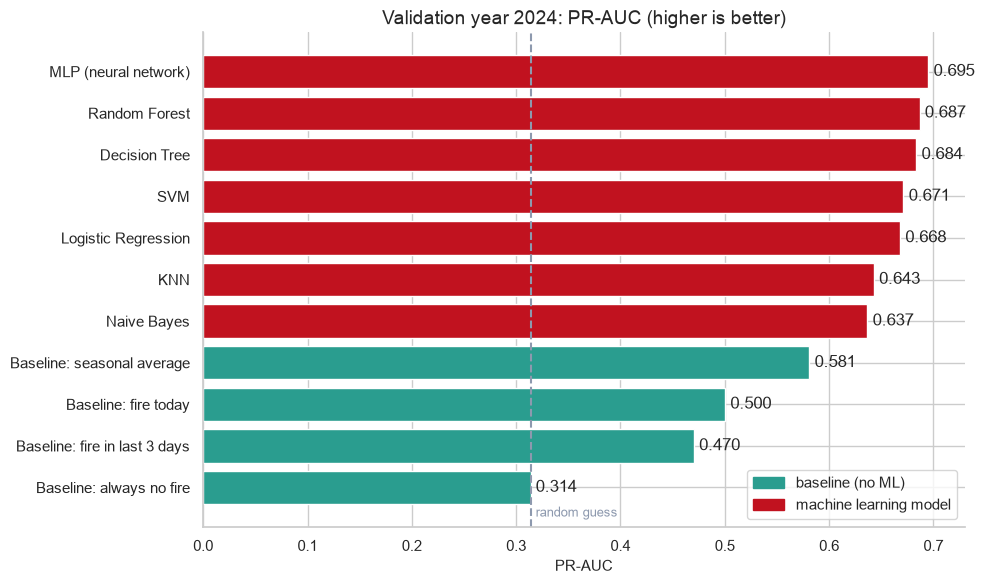

In [33]:
# graph 1: PR-AUC of every baseline and model
plot_data = results.sort_values("pr_auc")
colours = [TEAL if t == "baseline" else RED for t in plot_data["type"]]

plt.figure(figsize=(10, 6))
bars = plt.barh(plot_data["model"], plot_data["pr_auc"], color=colours)
for bar, value in zip(bars, plot_data["pr_auc"]):
    plt.text(value + 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center")
plt.axvline(y_valid.mean(), color=GREY, linestyle="--")
plt.text(y_valid.mean() + 0.005, -0.7, "random guess", color=GREY, fontsize=9)
plt.title("Validation year 2024: PR-AUC (higher is better)")
plt.xlabel("PR-AUC")
plt.ylabel("")
plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=TEAL),
                    plt.Rectangle((0, 0), 1, 1, color=RED)],
           labels=["baseline (no ML)", "machine learning model"], loc="lower right")
save_figure("07_pr_auc_comparison")

Saved graph: 07_precision_recall_f1.png


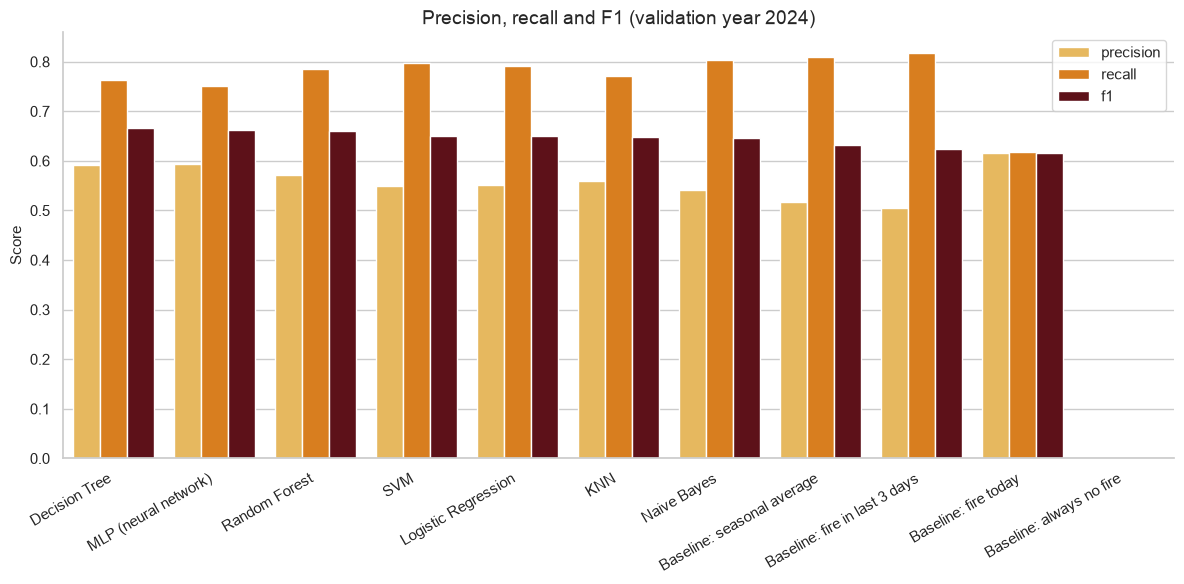

In [34]:
# graph 2: precision, recall and F1 together
long = results[show].melt(id_vars=["model", "type"], value_vars=["precision", "recall", "f1"],
                          var_name="metric", value_name="value")
order = list(results.sort_values("f1", ascending=False)["model"])

plt.figure(figsize=(12, 6))
sns.barplot(data=long, x="model", y="value", hue="metric", order=order,
            palette=[AMBER, ORANGE, DEEP_RED])
plt.xticks(rotation=30, ha="right")
plt.title("Precision, recall and F1 (validation year 2024)")
plt.xlabel("")
plt.ylabel("Score")
plt.legend(title="")
save_figure("07_precision_recall_f1")

Saved graph: 07_confusion_matrix.png


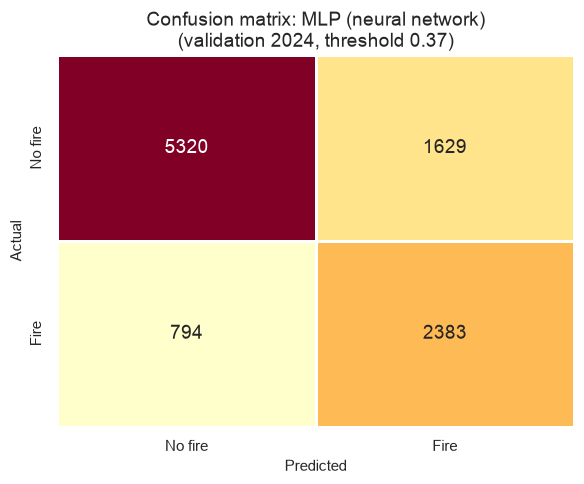

In [35]:
# graph 4: confusion matrix of the best model
best_row = results[results["model"] == best_name].iloc[0]
predicted = (curves[best_name] >= best_row["threshold"]).astype(int)
cm = confusion_matrix(y_valid, predicted)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlOrRd", linewidths=1, cbar=False,
            xticklabels=["No fire", "Fire"], yticklabels=["No fire", "Fire"],
            annot_kws={"size": 14})
plt.title(f"Confusion matrix: {best_name}\n(validation 2024, threshold {best_row['threshold']:.2f})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
save_figure("07_confusion_matrix")

Saved graph: 07_train_vs_valid_gap.png


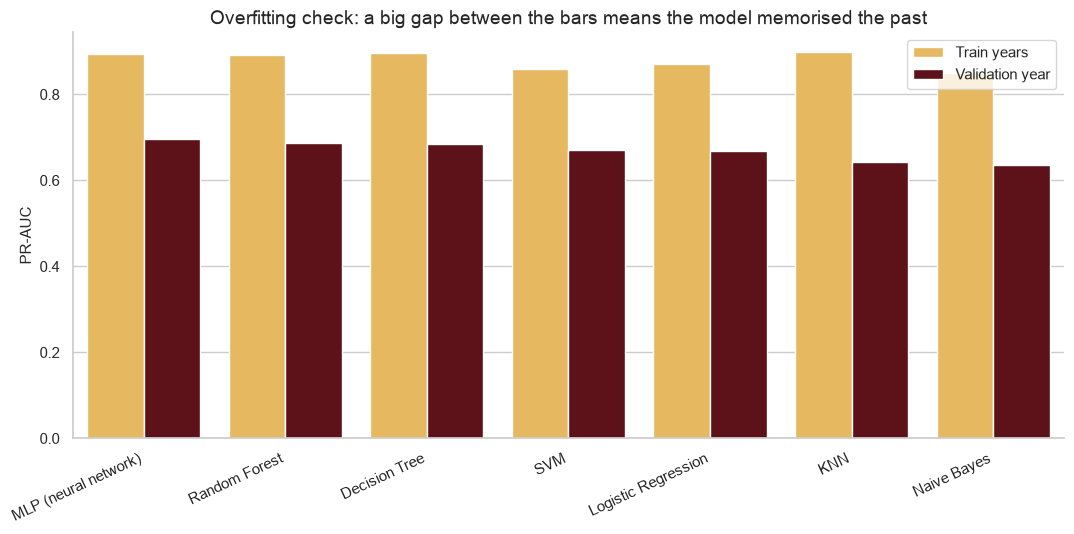

In [36]:
# graph 5: bias-variance check (train score vs validation score)
gap = models_only[["model", "train_pr_auc", "pr_auc"]].rename(
    columns={"train_pr_auc": "Train years", "pr_auc": "Validation year"})
gap = gap.melt(id_vars="model", var_name="data", value_name="PR-AUC")

plt.figure(figsize=(11, 5.5))
sns.barplot(data=gap, x="model", y="PR-AUC", hue="data", palette=[AMBER, DEEP_RED])
plt.xticks(rotation=25, ha="right")
plt.title("Overfitting check: a big gap between the bars means the model memorised the past")
plt.xlabel("")
plt.legend(title="")
save_figure("07_train_vs_valid_gap")

In [37]:
# step 5: save the choice for script 10
choice = {
    "model": best_name,
    "params": best_params[best_name],
    "threshold": float(best_row["threshold"]),
    "feature_columns": feature_cols,
}
with open(MODEL_DIR / "chosen_model.json", "w") as f:
    json.dump(choice, f, indent=2)

print()
print("Saved the choice:", best_name, "-> outputs/models/chosen_model.json")


Saved the choice: MLP (neural network) -> outputs/models/chosen_model.json


## 8. Regression\nHere we predict the number of fire detections for the next day. We compare simple linear, polynomial and multiple linear regression using MAE, MSE, RMSE and R-squared.

In [38]:
# load data (train and validation years only)
data = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"])
train = data[data["split"] == "train"]
valid = data[data["split"] == "valid"]

feature_cols = all_feature_columns(data.columns)
y_train = train["count_next_day"]
y_valid = valid["count_next_day"]

print("Average detections per cell-day  | train:", round(y_train.mean(), 2),
      "| valid:", round(y_valid.mean(), 2))
print("Maximum in one cell-day          | train:", int(y_train.max()),
      "| valid:", int(y_valid.max()))

Average detections per cell-day  | train: 6.18 | valid: 1.3
Maximum in one cell-day          | train: 246 | valid: 88


In [39]:
# a small function to score every model the same way
def regression_scores(name, y_true, y_pred):
    y_pred = np.clip(y_pred, 0, None)             # a count cannot be negative
    mse = mean_squared_error(y_true, y_pred)
    return {"model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R2": r2_score(y_true, y_pred)}

In [40]:
# baselines
rows = []
predictions = {}

predictions["Baseline: same as today"] = valid["fire_today"].values
predictions["Baseline: training average"] = np.full(len(valid), y_train.mean())

In [41]:
# simple linear regression (one feature: fires in the last 3 days)
simple = LinearRegression().fit(train[["fire_roll3"]], y_train)
predictions["Simple linear (fire_roll3)"] = simple.predict(valid[["fire_roll3"]])
print()
print("Simple linear: count_tomorrow = %.2f + %.3f x fire_roll3" % (simple.intercept_, simple.coef_[0]))


Simple linear: count_tomorrow = 0.65 + 0.298 x fire_roll3


In [42]:
# polynomial regression (degree 2 and 3 on the same feature)
for degree in [2, 3]:
    poly = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    poly.fit(train[["fire_roll3"]], y_train)
    predictions[f"Polynomial degree {degree} (fire_roll3)"] = poly.predict(valid[["fire_roll3"]])

In [43]:
# multiple linear regression (all features)
multiple = make_pipeline(StandardScaler(), LinearRegression()).fit(train[feature_cols], y_train)
predictions["Multiple linear (all features)"] = multiple.predict(valid[feature_cols])

In [44]:
# results table
for name, pred in predictions.items():
    rows.append(regression_scores(name, y_valid, pred))
results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
print()
print("REGRESSION RESULTS (validation year 2024). Lower MAE/RMSE is better, higher R2 is better.")
print(results.round(3).to_string(index=False))
results.to_csv(TABLE_DIR / "08_regression_results.csv", index=False)


REGRESSION RESULTS (validation year 2024). Lower MAE/RMSE is better, higher R2 is better.
                           model   MAE    MSE  RMSE     R2
  Multiple linear (all features) 1.540 10.128 3.183  0.206
      Simple linear (fire_roll3) 1.712 11.598 3.406  0.091
Polynomial degree 2 (fire_roll3) 1.603 11.919 3.452  0.066
Polynomial degree 3 (fire_roll3) 1.582 12.055 3.472  0.056
         Baseline: same as today 1.336 12.465 3.531  0.023
      Baseline: training average 5.612 36.630 6.052 -1.870


In [45]:
# OLS table (Ordinary Least Squares) with statsmodels
# This shows the coefficient of each feature. (Rows are not independent, so
# treat the p-values with care.)
# fire_roll3 is exactly fire_today + fire_lag1 + fire_lag2, so we leave it out here.
# (OLS cannot give clear coefficients when one column is a sum of other columns.)
ols_cols = [c for c in feature_cols if c != "fire_roll3"]
x_sm = sm.add_constant(train[ols_cols].astype(float))
ols = sm.OLS(y_train, x_sm).fit()
print()
print("OLS summary (training years): R-squared =", round(ols.rsquared, 3))
ols_table = pd.DataFrame({"coefficient": ols.params, "std_error": ols.bse, "p_value": ols.pvalues}).round(4)
print(ols_table)
ols_table.to_csv(TABLE_DIR / "08_ols_coefficients.csv")


OLS summary (training years): R-squared = 0.761
                 coefficient  std_error  p_value
const                 7.4561     4.2097   0.0765
day_of_year          -0.0182     0.0026   0.0000
cell_lat             -0.1816     0.0518   0.0005
cell_lon              0.0631     0.0489   0.1971
fire_today            0.3962     0.0096   0.0000
fire_lag1             0.1542     0.0085   0.0000
fire_lag2             0.0062     0.0086   0.4686
fire_roll7           -0.0079     0.0012   0.0000
days_since_fire      -0.0377     0.0042   0.0000
frp_roll3             0.0101     0.0006   0.0000
neighbour_today       0.0451     0.0020   0.0000
neighbour_roll3      -0.0076     0.0007   0.0000


Saved graph: 08_actual_vs_predicted.png


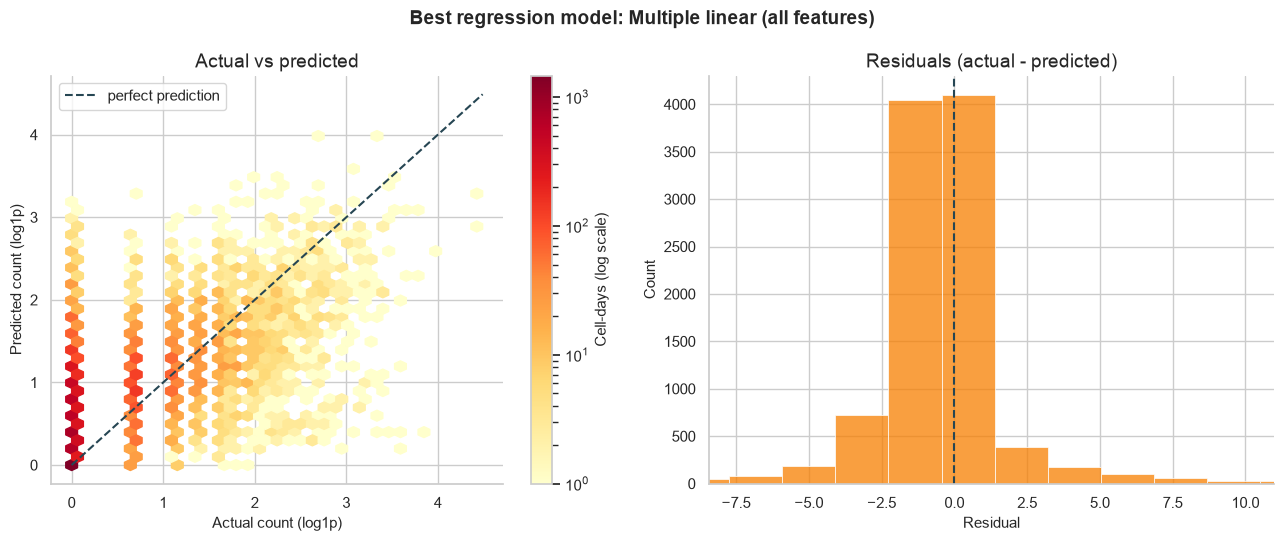


Look at the gap: R-squared is high on the training years but low on the validation year.
The reason is that 2024 had far fewer fires than 2020-2023 (see the averages at the top).
The size of the fires changed over the years, so a model learned on old years is off.

Remember: counts are very skewed (many zeros, few big values), so a linear model
is only a rough tool here. Compare with the baseline before you say anything.


In [46]:
# graph 2: actual vs predicted, and residuals (best model)
best_name = results.iloc[0]["model"]
best_pred = np.clip(predictions[best_name], 0, None)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
hb = axes[0].hexbin(np.log1p(y_valid), np.log1p(best_pred), gridsize=35, cmap="YlOrRd",
                    bins="log", mincnt=1)
limit = max(np.log1p(y_valid).max(), np.log1p(best_pred).max())
axes[0].plot([0, limit], [0, limit], color=NAVY, linestyle="--", label="perfect prediction")
axes[0].set_xlabel("Actual count (log1p)")
axes[0].set_ylabel("Predicted count (log1p)")
axes[0].set_title("Actual vs predicted")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="Cell-days (log scale)")

residual = y_valid.values - best_pred
sns.histplot(residual, bins=60, color=ORANGE, edgecolor="white", ax=axes[1])
axes[1].axvline(0, color=NAVY, linestyle="--")
axes[1].set_xlim(np.percentile(residual, 1), np.percentile(residual, 99))
axes[1].set_title("Residuals (actual - predicted)")
axes[1].set_xlabel("Residual")
plt.suptitle(f"Best regression model: {best_name}", fontsize=14, fontweight="bold")
save_figure("08_actual_vs_predicted")

print()
print("Look at the gap: R-squared is high on the training years but low on the validation year.")
print("The reason is that 2024 had far fewer fires than 2020-2023 (see the averages at the top).")
print("The size of the fires changed over the years, so a model learned on old years is off.")
print()
print("Remember: counts are very skewed (many zeros, few big values), so a linear model")
print("is only a rough tool here. Compare with the baseline before you say anything.")

## 9. K-Means clustering and PCA\nK-Means groups grid cells with similar fire patterns. PCA helps us study the main patterns in the input data. This section uses training data.

In [47]:
# make one row for every cell (training years, Oct-Nov only)
cell_day = pd.read_csv(PROCESSED_DIR / "cell_day.csv", parse_dates=["date"])
cell_day = cell_day[cell_day["year"].isin(TRAIN_YEARS) & cell_day["date"].dt.month.isin(SEASON_MONTHS)]

profile = cell_day.groupby("cell_id").agg(
    fire_day_share=("fire_count", lambda s: (s > 0).mean()),
    total_fires=("fire_count", "sum"),
    max_fires_one_day=("fire_count", "max"),
    frp_total=("frp_sum", "sum"))
profile["avg_frp"] = profile["frp_total"] / profile["total_fires"].replace(0, np.nan)
profile["avg_frp"] = profile["avg_frp"].fillna(0)

# the day of the year when the cell is busiest
peak_day = cell_day.groupby(["cell_id", cell_day["date"].dt.dayofyear.rename("doy")])["fire_count"].mean()
profile["peak_day"] = peak_day.groupby("cell_id").idxmax().apply(lambda pair: pair[1])
profile = profile.drop(columns="frp_total")

positions = cell_day.drop_duplicates("cell_id").set_index("cell_id")[["cell_lat", "cell_lon"]]
print("Cells:", len(profile))
print(profile.describe().round(2))

# these columns are very skewed (a few cells have huge values), so we take log1p first
# otherwise one strange cell can make a cluster of its own
skewed = ["total_fires", "max_fires_one_day", "avg_frp"]
profile_for_clustering = profile.copy()
profile_for_clustering[skewed] = np.log1p(profile_for_clustering[skewed])
scaled = StandardScaler().fit_transform(profile_for_clustering)

Cells: 166
       fire_day_share  total_fires  max_fires_one_day  avg_frp  peak_day
count          166.00       166.00             166.00   166.00    166.00
mean             0.42      1510.77              54.95     5.95    305.13
std              0.25      1795.29              63.21     5.02     13.26
min              0.00         0.00               0.00     0.00    274.00
25%              0.15        65.75               5.25     4.11    296.00
50%              0.53       686.00              29.00     5.42    309.00
75%              0.62      2260.50              78.00     7.24    315.00
max              0.77      6288.00             246.00    60.76    335.00



Silhouette score for each k: {2: 0.503, 3: 0.38, 4: 0.38, 5: 0.406, 6: 0.422}
Chosen k: 2
Saved graph: 09_choose_k.png


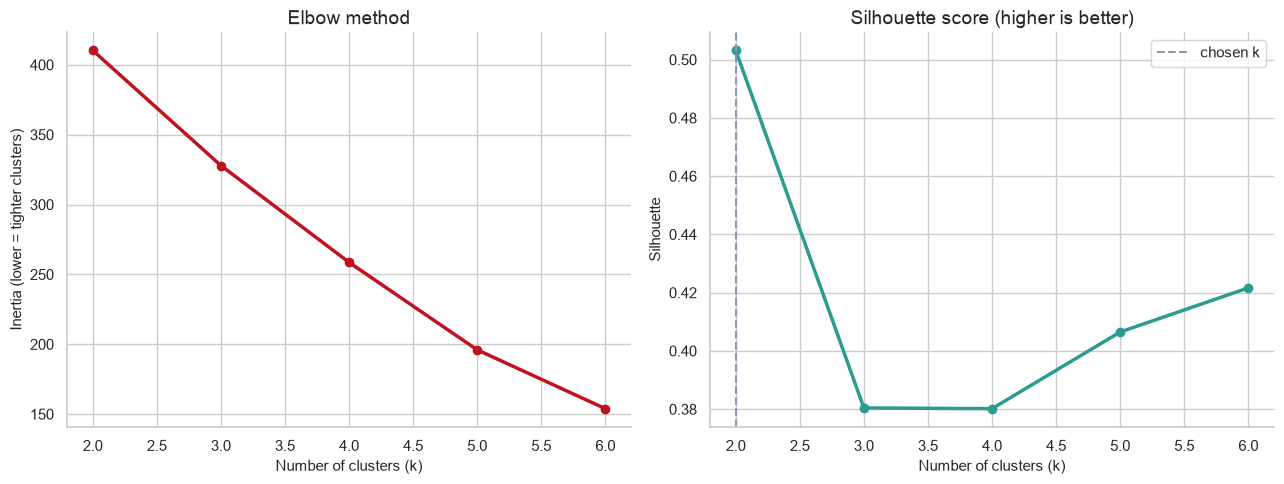

In [48]:
# choose the number of clusters (elbow and silhouette)
k_values = list(range(2, 7))
inertia = []
silhouette = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_SEED).fit(scaled)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(scaled, model.labels_))

# Rule: take the smallest k whose silhouette is close (within 0.01) to the best one.
# Fewer clusters are easier to explain.
best_silhouette = max(silhouette)
best_k = 0
for k, score in zip(k_values, silhouette):
    if score >= best_silhouette - 0.01:
        best_k = k
        break
print()
print("Silhouette score for each k:", {k: round(float(sc), 3) for k, sc in zip(k_values, silhouette)})
print("Chosen k:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(k_values, inertia, marker="o", color=RED, linewidth=2.5)
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (lower = tighter clusters)")
axes[1].plot(k_values, silhouette, marker="o", color=TEAL, linewidth=2.5)
axes[1].axvline(best_k, color=GREY, linestyle="--", label="chosen k")
axes[1].legend()
axes[1].set_title("Silhouette score (higher is better)")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette")
save_figure("09_choose_k")

Saved graph: 09_random_init_trap.png


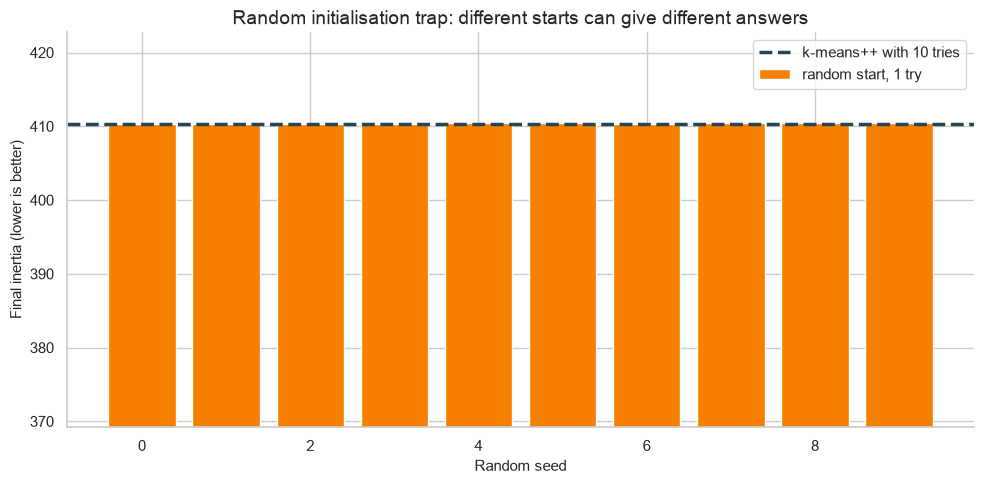

In [49]:
# the random initialisation trap
# With "random" start and only 1 try, K-Means can end in a bad answer.
# "k-means++" start with several tries is safer.
random_inertia = []
for seed in range(10):
    m = KMeans(n_clusters=best_k, init="random", n_init=1, random_state=seed).fit(scaled)
    random_inertia.append(m.inertia_)
good = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=RANDOM_SEED).fit(scaled)

plt.figure(figsize=(10, 5))
plt.bar(range(10), random_inertia, color=ORANGE, label="random start, 1 try")
plt.axhline(good.inertia_, color=NAVY, linewidth=2.5, linestyle="--", label="k-means++ with 10 tries")
plt.ylim(min(random_inertia + [good.inertia_]) * 0.9, max(random_inertia) * 1.03)
plt.xlabel("Random seed")
plt.ylabel("Final inertia (lower is better)")
plt.title("Random initialisation trap: different starts can give different answers")
plt.legend()
save_figure("09_random_init_trap")

In [50]:
# final K-Means: name the clusters by activity (0 = quietest)
profile["raw_label"] = good.labels_
order = profile.groupby("raw_label")["fire_day_share"].mean().sort_values().index
rename = {old: new for new, old in enumerate(order)}
profile["cluster"] = profile["raw_label"].map(rename)
profile = profile.drop(columns="raw_label").join(positions)

cluster_summary = profile.groupby("cluster")[["fire_day_share", "total_fires", "max_fires_one_day",
                                              "avg_frp", "peak_day"]].mean().round(2)
cluster_summary["cells"] = profile.groupby("cluster").size()
print()
print("K-MEANS CLUSTERS (0 = quietest, higher = more fire activity)")
print(cluster_summary)
profile.to_csv(TABLE_DIR / "09_cell_clusters.csv")
cluster_summary.to_csv(TABLE_DIR / "09_cluster_summary.csv")


K-MEANS CLUSTERS (0 = quietest, higher = more fire activity)
         fire_day_share  total_fires  max_fires_one_day  avg_frp  peak_day  \
cluster                                                                      
0                  0.09        41.38               3.70     5.51    300.77   
1                  0.58      2199.95              78.99     6.16    307.17   

         cells  
cluster         
0           53  
1          113  


Saved graph: 09_cluster_map.png


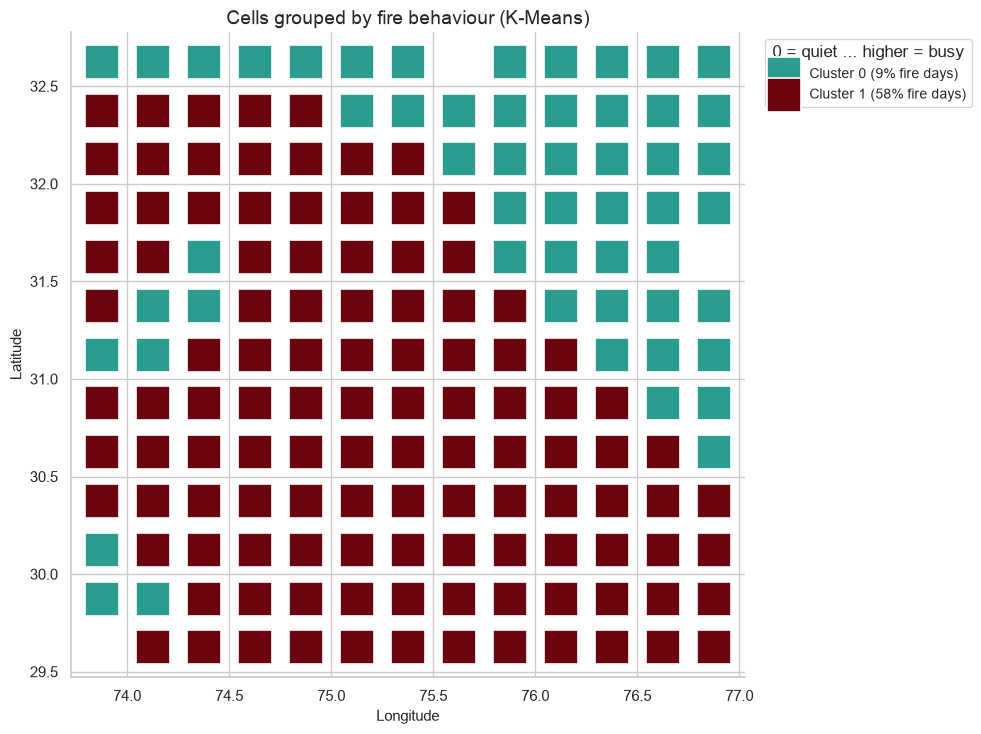

In [51]:
# graph: map of the clusters
# quiet clusters get cool colours, busy clusters get hot colours
palette = [TEAL, AMBER, ORANGE, RED, DEEP_RED]
n_clusters = profile["cluster"].nunique()
CLUSTER_COLOURS = [palette[i] for i in np.linspace(0, len(palette) - 1, n_clusters).round().astype(int)]

plt.figure(figsize=(10, 7.5))
for c in sorted(profile["cluster"].unique()):
    part = profile[profile["cluster"] == c]
    plt.scatter(part["cell_lon"], part["cell_lat"], s=620, marker="s", color=CLUSTER_COLOURS[c],
                edgecolor="white", linewidth=1.2,
                label=f"Cluster {c} ({cluster_summary.loc[c, 'fire_day_share']:.0%} fire days)")
plt.title("Cells grouped by fire behaviour (K-Means)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="0 = quiet ... higher = busy", loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=10)
save_figure("09_cluster_map")

In [52]:
# load training and validation rows
data = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"])
train = data[data["split"] == "train"]
valid = data[data["split"] == "valid"]
feature_cols = all_feature_columns(data.columns)

scaler = StandardScaler().fit(train[feature_cols])          # fitted on train only
x_train = scaler.transform(train[feature_cols])
x_valid = scaler.transform(valid[feature_cols])

pca = PCA().fit(x_train)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_90 = int(np.argmax(cumulative >= 0.90) + 1)
print()
print("PCA: components needed for 90% of the variance:", n_90, "out of", len(feature_cols))


PCA: components needed for 90% of the variance: 5 out of 12


Saved graph: 09_pca_scree.png


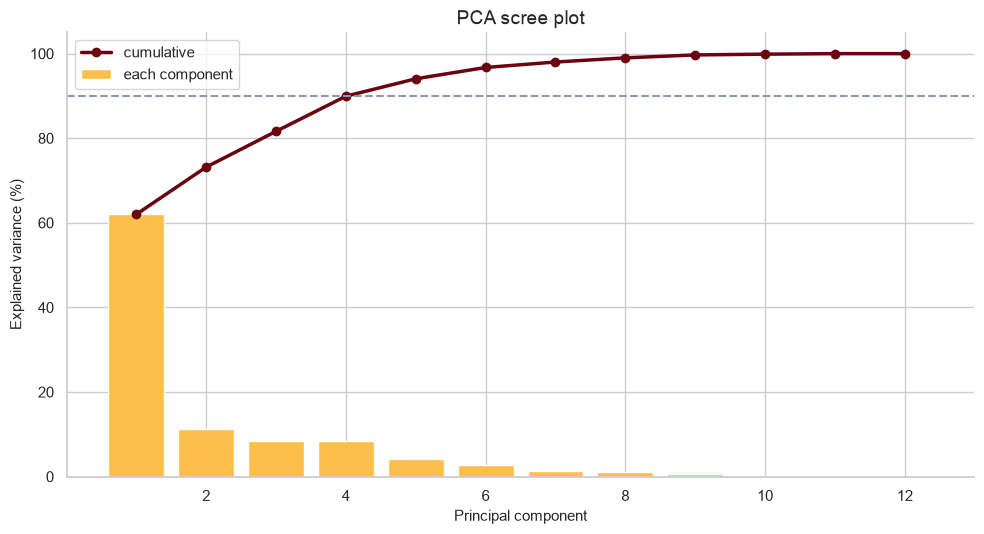

In [53]:
# graph: scree plot
plt.figure(figsize=(10, 5.5))
plt.bar(range(1, len(explained) + 1), explained * 100, color=AMBER, label="each component")
plt.plot(range(1, len(explained) + 1), cumulative * 100, color=DEEP_RED, marker="o",
         linewidth=2.5, label="cumulative")
plt.axhline(90, color=GREY, linestyle="--")
plt.title("PCA scree plot")
plt.xlabel("Principal component")
plt.ylabel("Explained variance (%)")
plt.legend()
save_figure("09_pca_scree")

Saved graph: 09_pca_scatter.png


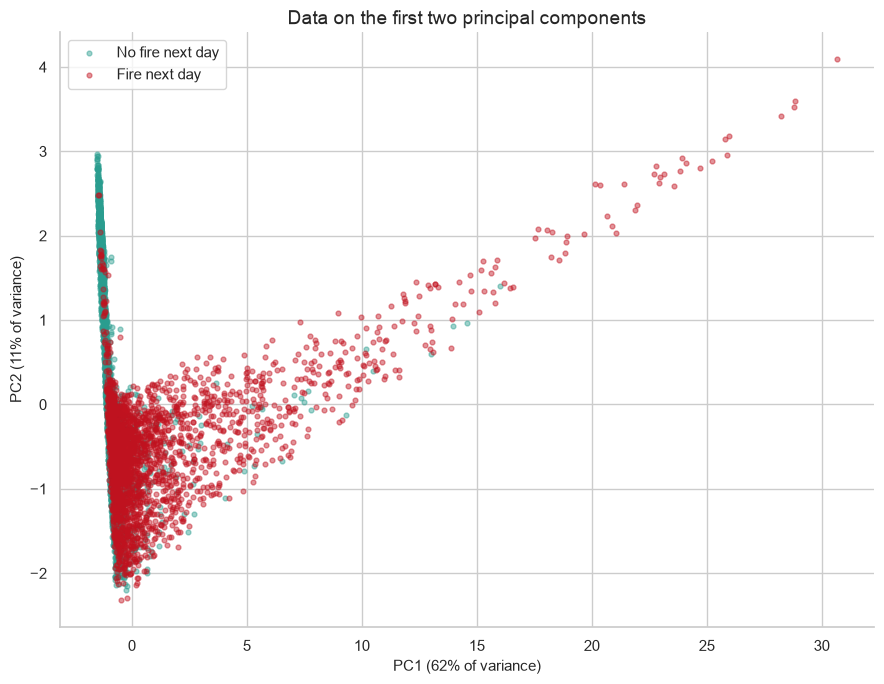

In [54]:
# graph: first two components, coloured by the target
two = PCA(n_components=2).fit(x_train)
points = two.transform(x_train)
sample = np.random.RandomState(RANDOM_SEED).choice(len(points), size=min(6000, len(points)), replace=False)
target = train["fire_next_day"].values[sample]

plt.figure(figsize=(9, 7))
plt.scatter(points[sample][target == 0, 0], points[sample][target == 0, 1], s=12, alpha=0.45,
            color=TEAL, label="No fire next day")
plt.scatter(points[sample][target == 1, 0], points[sample][target == 1, 1], s=12, alpha=0.45,
            color=RED, label="Fire next day")
plt.title("Data on the first two principal components")
plt.xlabel(f"PC1 ({two.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({two.explained_variance_ratio_[1]:.0%} of variance)")
plt.legend()
save_figure("09_pca_scatter")

## 10. Final test and prediction\nIn this section, we evaluate the selected model using 2025 data. We also show how to make a prediction for a selected grid cell and date.

In [55]:
# load data and the choice made in script 07
data = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"])
train = data[data["split"] == "train"].reset_index(drop=True)
valid = data[data["split"] == "valid"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)
train_valid = pd.concat([train, valid], ignore_index=True)

with open(MODEL_DIR / "chosen_model.json") as f:
    choice = json.load(f)

model_name = choice["model"]
feature_cols = choice["feature_columns"]
threshold = choice["threshold"]
print("Chosen model :", model_name)
print("Settings     :", choice["params"])
print("Threshold    :", round(threshold, 3), "(chosen on the validation year)")
print("Test rows    :", len(test), "| fire share in test year:", round(test["fire_next_day"].mean(), 3))

Chosen model : MLP (neural network)
Settings     : {'model__alpha': 0.0001, 'model__hidden_layer_sizes': [32, 16]}
Threshold    : 0.375 (chosen on the validation year)
Test rows    : 10126 | fire share in test year: 0.25


In [56]:
# fit the final model on train + validation years
recipe = get_recipes()[model_name]
final_model = clone(recipe["pipe"]).set_params(**choice["params"])
fit_data = shrink(train_valid, recipe["max_rows"])
final_model.fit(fit_data[feature_cols], fit_data["fire_next_day"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['day_of_year','cell_lat','cell_lon',...,'frp_roll3','neighbour_today', 'neighbour_roll3']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [57]:
# score the test year: final model and baselines
y_test = test["fire_next_day"]
test_prob = final_model.predict_proba(test[feature_cols])[:, 1]

results = []
row = get_scores(y_test, test_prob, threshold)
row.update({"model": "FINAL MODEL: " + model_name, "type": "model"})
results.append(row)

# baselines: seasonal average is learnt from train + validation years.
# its threshold comes from the validation year (same rule as for the model)
valid_baselines = baseline_scores(train, valid)
test_baselines = baseline_scores(train_valid, test)
curves = {"final model": test_prob}

for name, (score, is_prob) in test_baselines.items():
    if is_prob:
        t = best_threshold(valid["fire_next_day"], valid_baselines[name][0])
    else:
        t = 0.5
    row = get_scores(y_test, score, t, is_prob)
    row.update({"model": name, "type": "baseline"})
    results.append(row)
    curves[name] = score

results = pd.DataFrame(results).sort_values("pr_auc", ascending=False).reset_index(drop=True)
show = ["model", "precision", "recall", "f1", "pr_auc", "roc_auc", "log_loss", "accuracy"]
print()
print("TEST RESULTS (year 2025)")
print(results[show].round(3).to_string(index=False))
results.to_csv(TABLE_DIR / "10_test_results.csv", index=False)

final_row = results[results["type"] == "model"].iloc[0]
best_baseline = results[results["type"] == "baseline"].iloc[0]
print()
if final_row["pr_auc"] > best_baseline["pr_auc"]:
    print("The final model has a higher PR-AUC than the best baseline:",
          round(final_row["pr_auc"], 3), "vs", round(best_baseline["pr_auc"], 3))
else:
    print("The final model does NOT beat the best baseline on PR-AUC:",
          round(final_row["pr_auc"], 3), "vs", round(best_baseline["pr_auc"], 3))
    print("Write this honestly in the report.")


TEST RESULTS (year 2025)
                            model  precision  recall    f1  pr_auc  roc_auc  log_loss  accuracy
FINAL MODEL: MLP (neural network)      0.640   0.717 0.676   0.730    0.883     0.361     0.828
       Baseline: seasonal average      0.447   0.879 0.592   0.591    0.835     0.510     0.697
             Baseline: fire today      0.606   0.607 0.607   0.467    0.738       NaN     0.803
    Baseline: fire in last 3 days      0.502   0.825 0.624   0.458    0.776       NaN     0.751
         Baseline: always no fire      0.000   0.000 0.000   0.250    0.500       NaN     0.750

The final model has a higher PR-AUC than the best baseline: 0.73 vs 0.591


Saved graph: 10_test_comparison.png


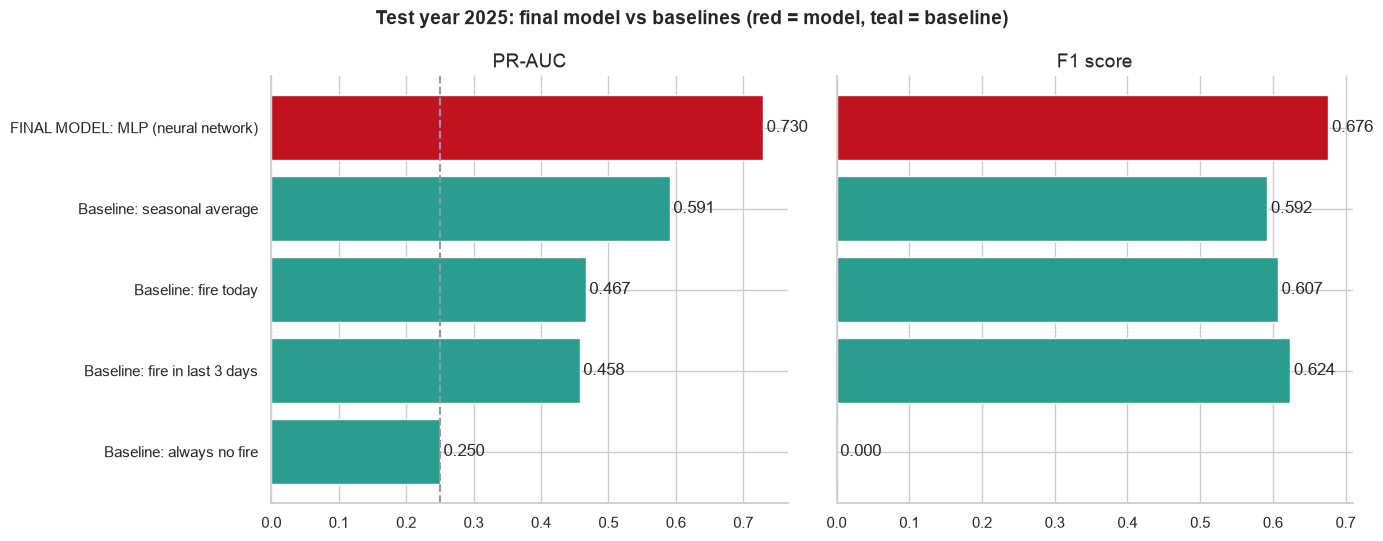

In [58]:
# graph 1: final comparison
plot_data = results.sort_values("pr_auc")
colours = [RED if t == "model" else TEAL for t in plot_data["type"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, metric, title in zip(axes, ["pr_auc", "f1"], ["PR-AUC", "F1 score"]):
    bars = ax.barh(plot_data["model"], plot_data[metric], color=colours)
    for bar, value in zip(bars, plot_data[metric]):
        ax.text(value + 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center")
    ax.set_title(title)
    ax.set_xlabel("")
axes[0].axvline(y_test.mean(), color=GREY, linestyle="--")
plt.suptitle("Test year 2025: final model vs baselines (red = model, teal = baseline)",
             fontsize=14, fontweight="bold")
save_figure("10_test_comparison")

Saved graph: 10_test_confusion_matrix.png


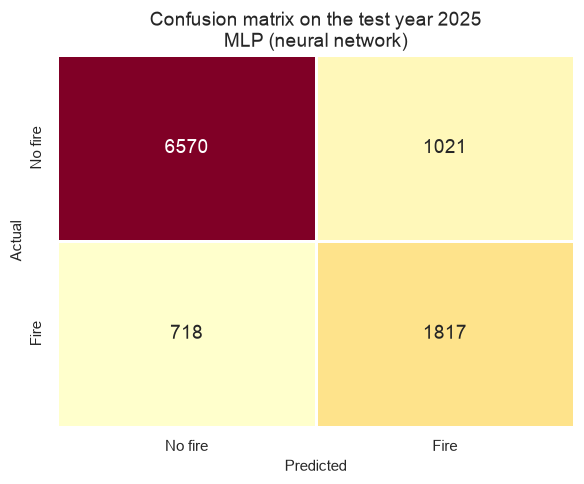

In [59]:
# graph 3: confusion matrix
predicted = (test_prob >= threshold).astype(int)
cm = confusion_matrix(y_test, predicted)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlOrRd", linewidths=1, cbar=False,
            xticklabels=["No fire", "Fire"], yticklabels=["No fire", "Fire"], annot_kws={"size": 14})
plt.title(f"Confusion matrix on the test year 2025\n{model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
save_figure("10_test_confusion_matrix")

In [60]:
# save the final model
saved = {"model": final_model, "model_name": model_name, "threshold": threshold,
         "feature_columns": feature_cols,
         "trained_on_years": TRAIN_YEARS + VALID_YEARS,
         "season_months": SEASON_MONTHS}
joblib.dump(saved, MODEL_DIR / "final_model.joblib")
print()
print("Saved: outputs/models/final_model.joblib")


# =====================================================================
# PREDICTION FUNCTION (Phase 8)
# =====================================================================


Saved: outputs/models/final_model.joblib


In [61]:
# Prepare the historical data for a new prediction
history = pd.read_csv(PROCESSED_DIR / "cell_day.csv", parse_dates=["date"])
all_features = build_features(history)


def predict_next_day(cell_id, day):
    """Predict the chance of a fire detection in a cell on the following day."""
    saved_model = joblib.load(MODEL_DIR / "final_model.joblib")
    day = pd.Timestamp(day)

    if cell_id not in set(all_features["cell_id"]):
        raise ValueError("This cell is not in the study area.")

    if day.month not in saved_model["season_months"]:
        raise ValueError("The model is trained for October and November only.")

    row = all_features[
        (all_features["cell_id"] == cell_id)
        & (all_features["date"] == day)
    ]

    if len(row) == 0:
        raise ValueError("No data is available for this date.")

    x = row[saved_model["feature_columns"]]

    if x.isna().any(axis=1).iloc[0]:
        raise ValueError("Some feature values are missing.")

    probability = float(
        saved_model["model"].predict_proba(x)[0, 1]
    )

    return {
        "cell_id": cell_id,
        "date": day.date(),
        "prediction_for": (day + pd.Timedelta(days=1)).date(),
        "fire_probability": round(probability, 3),
        "fire_predicted": probability >= saved_model["threshold"]
    }

In [62]:
# try the function (these are past days, so we can also see what really happened)
busy_cells = test.groupby("cell_id")["fire_count"].sum().sort_values(ascending=False)
example_cell = busy_cells.index[0]

print()
print("EXAMPLES")
for day in ["2025-10-20", "2025-11-05", "2025-11-15"]:
    answer = predict_next_day(example_cell, day)
    real = history[(history["cell_id"] == example_cell) &
                   (history["date"] == pd.Timestamp(day) + pd.Timedelta(days=1))]["fire_count"].iloc[0]
    print(answer)
    print("   what really happened the next day: fire detections =", int(real))

print()
print("EXAMPLES OF REFUSED REQUESTS")
for cell, day in [(example_cell, "2025-09-01"), ("999_999", "2025-11-05"), (example_cell, "2026-11-05")]:
    try:
        predict_next_day(cell, day)
    except ValueError as error:
        print("Refused:", error)


EXAMPLES
{'cell_id': '122_295', 'date': datetime.date(2025, 10, 20), 'prediction_for': datetime.date(2025, 10, 21), 'fire_probability': 0.976, 'fire_predicted': True}
   what really happened the next day: fire detections = 15
{'cell_id': '122_295', 'date': datetime.date(2025, 11, 5), 'prediction_for': datetime.date(2025, 11, 6), 'fire_probability': 0.63, 'fire_predicted': True}
   what really happened the next day: fire detections = 1
{'cell_id': '122_295', 'date': datetime.date(2025, 11, 15), 'prediction_for': datetime.date(2025, 11, 16), 'fire_probability': 0.163, 'fire_predicted': False}
   what really happened the next day: fire detections = 0

EXAMPLES OF REFUSED REQUESTS
Refused: The model is trained for October and November only.
Refused: This cell is not in the study area.
Refused: No data is available for this date.


## Notes for the report

- The data contains satellite fire detections, not confirmed stubble-burning incidents.
- The study area is a rectangular area around Punjab and may include nearby locations.
- The model uses historical fire activity, nearby-cell activity and calendar information.
- The data is split by year: 2020-2023 training, 2024 validation and 2025 testing.
- This is an academic prediction project, not an official early-warning system.

In [63]:
final_model.fit(fit_data[feature_cols], fit_data["fire_next_day"])
print("Final model trained successfully.")

Final model trained successfully.
